## All imports

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Reading files

In [41]:
# Set up dataframe
fraud_data = pd.read_csv('fraud_data.csv')
clean_data = pd.read_csv('advertising_funnel_clean.csv')

In [42]:
# fixing indexes in columns
stage_order = [
    'interest',
    'consideration',
    'intent',
    'purchase'
]

In [43]:
# converting values to numeric format
stage_map = {
    'interest': 0,
    'consideration': 1,
    'intent': 2,
    'purchase': 3
}

fraud_data['funnel_stage_num'] = (
    fraud_data['funnel_stage'].map(stage_map)
)

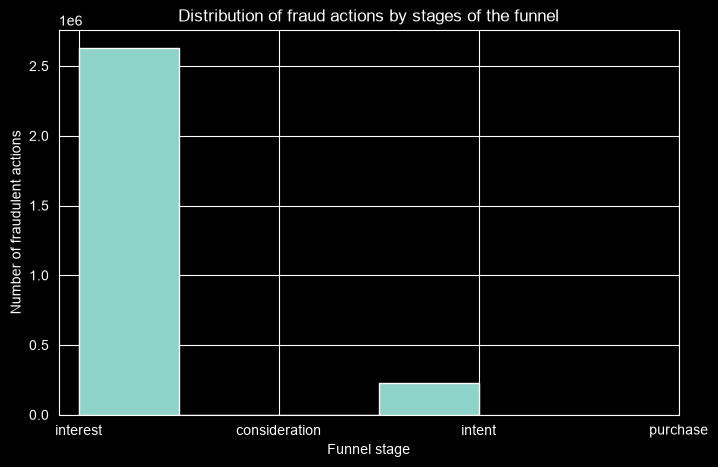

In [44]:
# creating a graph
plt.figure(figsize=(8, 5))

plt.hist(
    fraud_data['funnel_stage_num'],
    bins=4,
)

plt.xticks(
    [0, 1, 2, 3],
    stage_order
)

plt.xlabel('Funnel stage')
plt.ylabel('Number of fraudulent actions')
plt.title('Distribution of fraud actions by stages of the funnel')

plt.show()

In [45]:
# back up the graph with statistical values
fraud_data['funnel_stage'].value_counts()

funnel_stage
interest    2628724
intent       230282
Name: count, dtype: int64

In [46]:
# Percentage equivalent
fraud_data['funnel_stage'].value_counts(normalize=True) * 100

funnel_stage
interest    91.945382
intent       8.054618
Name: proportion, dtype: float64

### Conclusion

Based on the data obtained, we can say that the initial stages were the most vulnerable to fraud, it is much easier to follow the link than to finish paying, because it is not difficult to get bots to such stages, which causes fake results of user interest.

In [47]:
# creating a funnel
funnel = (
    clean_data
    .groupby(['ad_channel', 'funnel_stage'])['user_id']
    .nunique()
    .reset_index(name='users')
)

In [48]:
# encoding the values
funnel['funnel_stage'] = pd.Categorical(
    funnel['funnel_stage'],
    categories=stage_order,
    ordered=True
)

funnel = funnel.sort_values(
    ['ad_channel', 'funnel_stage']
)
# check
funnel

,ad_channel,funnel_stage,users
2,banner,interest,92003
0,banner,consideration,47541
1,banner,intent,7625
3,banner,purchase,688
6,native,interest,19381
4,native,consideration,12597
5,native,intent,412
7,native,purchase,37
10,organic_traffic,interest,78706
8,organic_traffic,consideration,53592


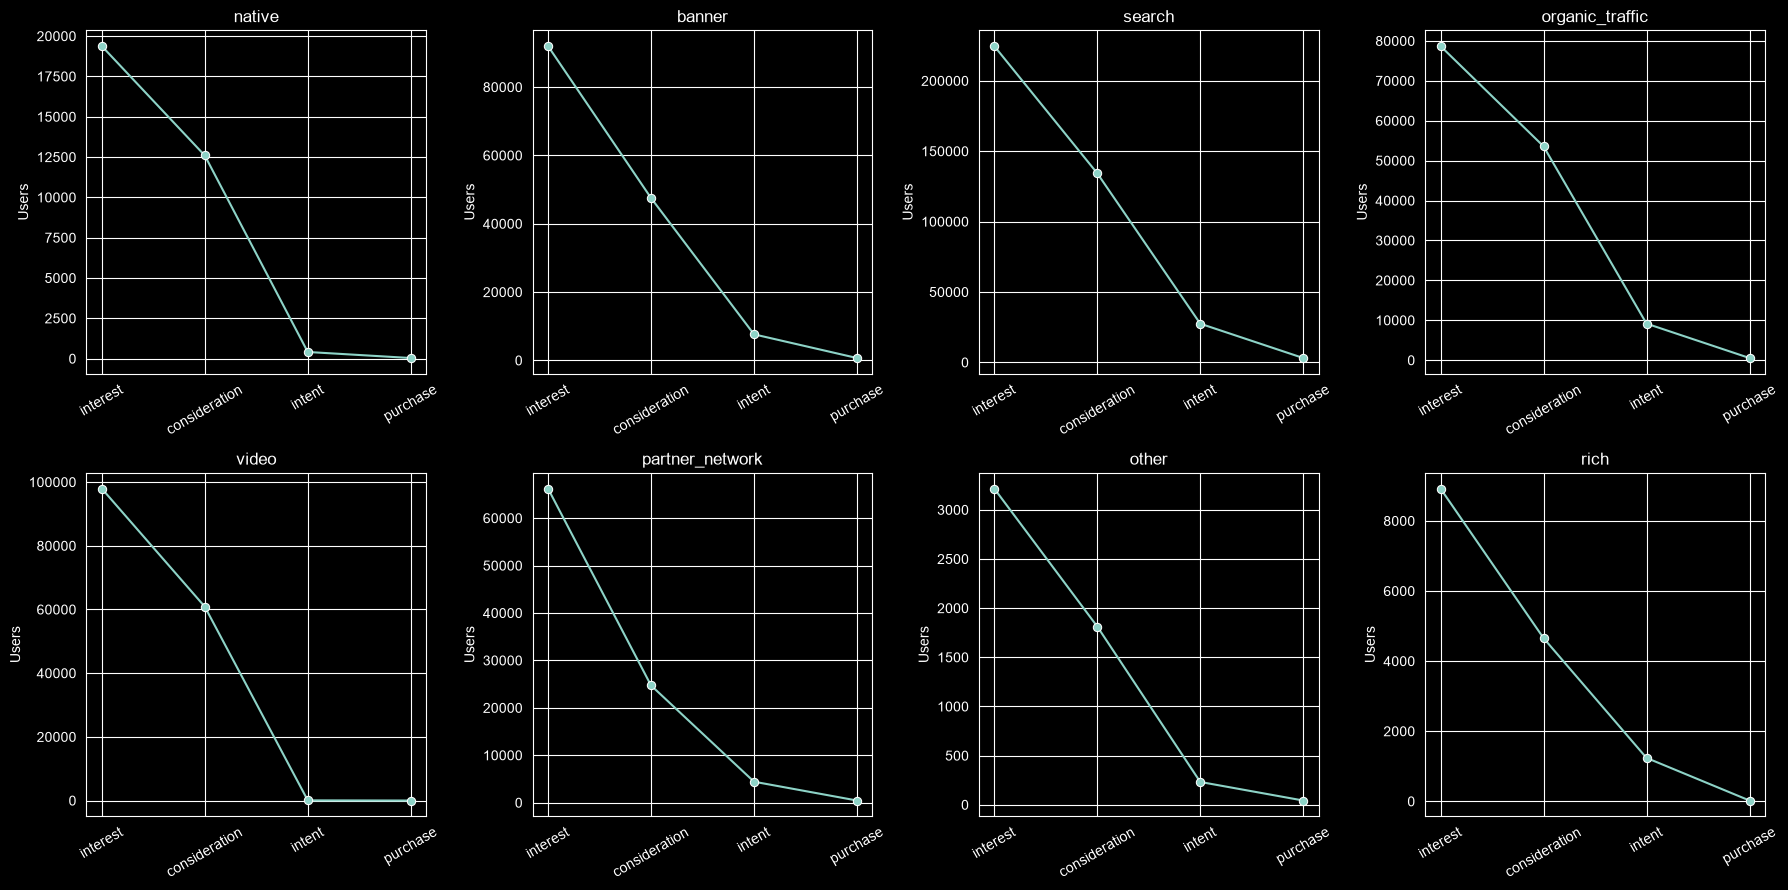

In [49]:
# creating a graph; I arrange it in 2 lines of 4 columns for readability
channels = clean_data['ad_channel'].unique()

fig, axes = plt.subplots(
    2,
    4,
    figsize=(18, 9)
)

axes = axes.flatten()

for ax, channel in zip(axes, channels):

    data = funnel[
        funnel['ad_channel'] == channel
    ]

    sns.lineplot(
        data=data,
        x='funnel_stage',
        y='users',
        marker='o',
        ax=ax
    )

    ax.set_title(channel)
    ax.set_xlabel('')
    ax.set_ylabel('Users')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

In [50]:
# Calculating the conversion rate
funnel_table = (
    clean_data
    .groupby(['ad_channel', 'funnel_stage'])['user_id']
    .nunique()
    .unstack(fill_value=0)
)

In [51]:
# put the funnels in the correct order
funnel_table = funnel_table[stage_order]

In [52]:
# conversion to purchase calculat
funnel_table['conversion_to_purchase'] = (
    funnel_table['purchase']
    / funnel_table['interest']
    * 100
)

In [53]:
# Sorting values by conversion
funnel_table.sort_values('conversion_to_purchase')

funnel_stage,interest,consideration,intent,purchase,conversion_to_purchase
ad_channel,,,,,
video,97960,60880,58,5,0.005104
native,19381,12597,412,37,0.190909
rich,8922,4657,1238,22,0.246581
partner_network,66234,24721,4420,450,0.679409
organic_traffic,78706,53592,9163,542,0.688639
banner,92003,47541,7625,688,0.747802
other,3216,1813,232,43,1.337065
search,224667,134305,27481,3090,1.375369


### Conclusion

Based on the conversion results and graphs, we see that the video channel shows the worst results, where there is a high level of engagement, but in the last stages there is a huge gap, that the consideration stage has over 60,000 people, but only 58 reach the next stage, and after 5. This is a sign of low channel efficiency.

In [54]:
# count the costs
costs = (
    clean_data
    .groupby('ad_channel')['price']
    .sum()
    .reset_index(name='cost')
)

In [55]:
# Count the profits
profits = (
    clean_data[
        clean_data['funnel_stage'] == 'purchase'
    ]
    .groupby('ad_channel')['profit']
    .sum()
    .reset_index(name='profit')
)

In [56]:
# Concatenation
channel_finance = costs.merge(
    profits,
    on='ad_channel',
    how='left'
)

channel_finance

,ad_channel,cost,profit
0,banner,73928.50,497881.0
1,native,64854.00,37355.0
2,organic_traffic,0.00,367094.0
3,other,0.00,28354.0
4,partner_network,95825.00,445411.0
5,rich,37097.50,33511.0
6,search,584314.50,2112193.0
7,video,119177.25,4582.0


In [57]:
# counting net profit
channel_finance['net_profit'] = (
    channel_finance['profit']
    - channel_finance['cost']
)

In [58]:
# creating the table
channel_finance.sort_values(
    'net_profit',
    ascending=False
)

,ad_channel,cost,profit,net_profit
6,search,584314.50,2112193.0,1527878.50
0,banner,73928.50,497881.0,423952.50
2,organic_traffic,0.00,367094.0,367094.00
4,partner_network,95825.00,445411.0,349586.00
3,other,0.00,28354.0,28354.00
5,rich,37097.50,33511.0,-3586.50
1,native,64854.00,37355.0,-27499.00
7,video,119177.25,4582.0,-114595.25


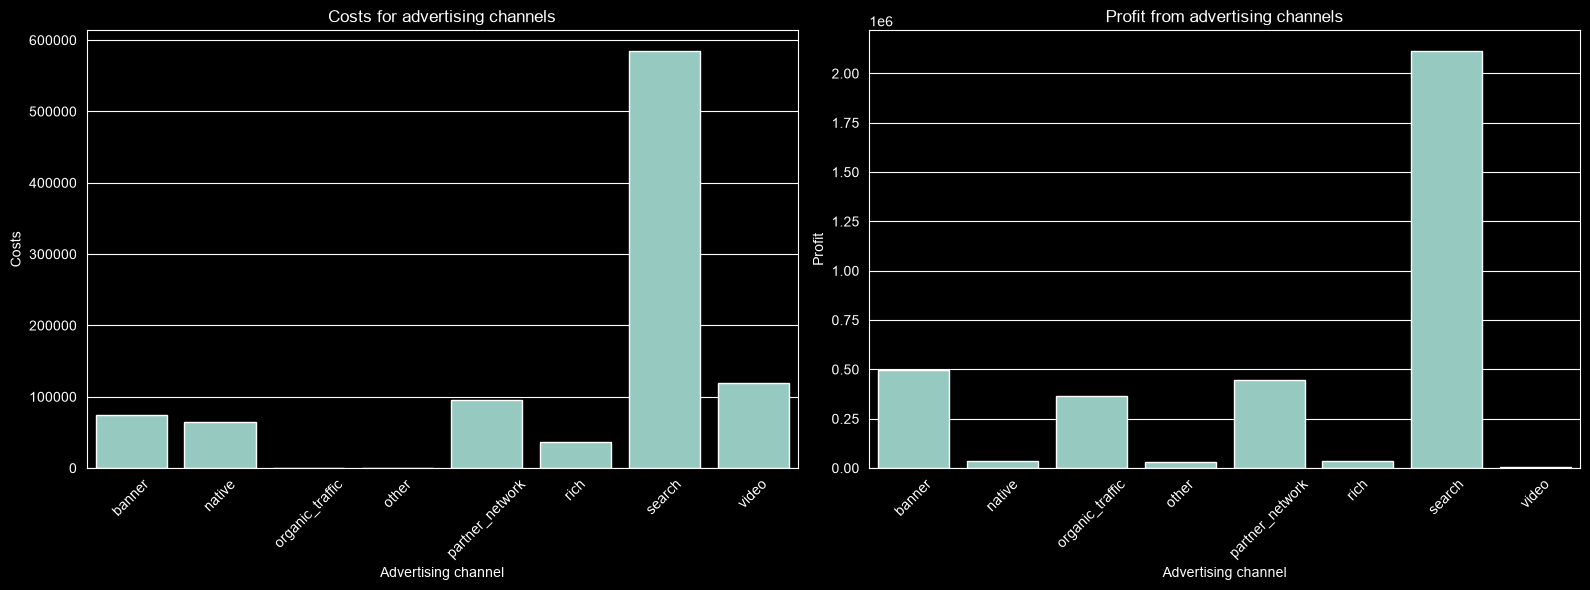

In [64]:
# create a graph next to each other for clarity.
fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6)
)

sns.barplot(
    data=channel_finance,
    x='ad_channel',
    y='cost',
    ax=axes[0]
)

axes[0].set_title('Costs for advertising channels')
axes[0].set_xlabel('Advertising channel')
axes[0].set_ylabel('Costs')
axes[0].tick_params(axis='x', rotation=45)


sns.barplot(
    data=channel_finance,
    x='ad_channel',
    y='profit',
    ax=axes[1]
)

axes[1].set_title('Profit from advertising channels')
axes[1].set_xlabel('Advertising channel')
axes[1].set_ylabel('Profit')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

The location of 2 graphs side by side immediately shows the client the situation of his campaign

In [60]:
# count users from different channels
os_distribution = (
    clean_data
    .groupby(['ad_channel', 'os'])['user_id']
    .nunique()
    .reset_index(name='users')
)

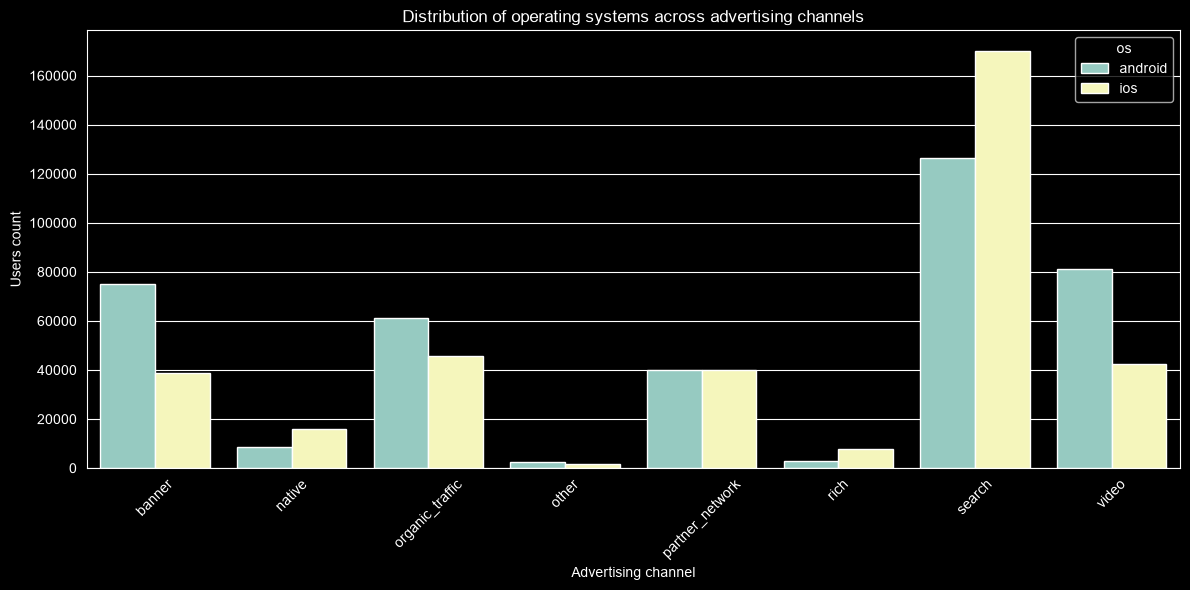

In [65]:
# graph
plt.figure(figsize=(12, 6))

sns.barplot(
    data=os_distribution,
    x='ad_channel',
    y='users',
    hue='os'
)

plt.xlabel('Advertising channel')
plt.ylabel('Users count')
plt.title('Distribution of operating systems across advertising channels')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [66]:
# Percentage
os_count = (
    clean_data
    .groupby(['ad_channel', 'os'])['user_id']
    .nunique()
    .reset_index(name='users')
)

os_count['percent'] = (
    os_count['users']
    / os_count.groupby('ad_channel')['users'].transform('sum')
    * 100
)

os_count

,ad_channel,os,users,percent
0,banner,android,74952,65.951587
1,banner,ios,38695,34.048413
2,native,android,8594,34.790705
3,native,ios,16108,65.209295
4,organic_traffic,android,61016,57.229684
5,organic_traffic,ios,45600,42.770316
6,other,android,2425,58.167426
7,other,ios,1744,41.832574
8,partner_network,android,39947,49.997497
9,partner_network,ios,39951,50.002503


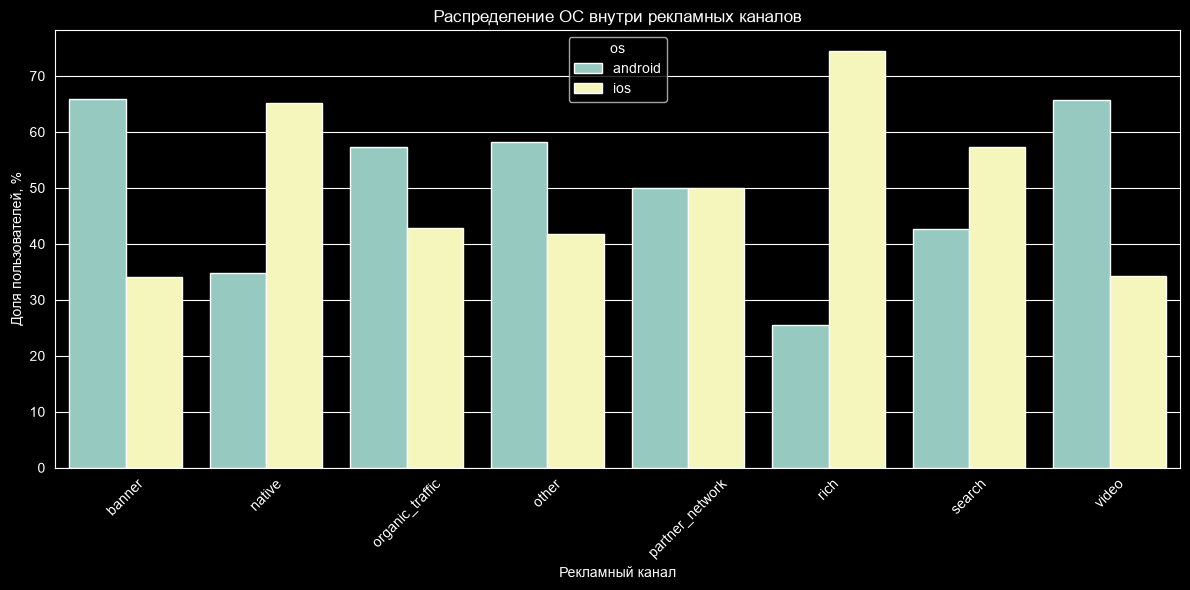

In [63]:
# построим процентное соотношение
plt.figure(figsize=(12, 6))

sns.barplot(
    data=os_count,
    x='ad_channel',
    y='percent',
    hue='os'
)

plt.xlabel('Рекламный канал')
plt.ylabel('Доля пользователей, %')
plt.title('Распределение ОС внутри рекламных каналов')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Conclusion

Based on the conversion rate, I can say that iOS users are more solvent and the OS can potentially influence user conversion, which was also indirectly justified in the previous module by the OS's slight dependence on financial indicators.